# Demos: Lecture 10

In [1]:
import pennylane as qp
import numpy as np
import matplotlib.pyplot as plt

## Demo 1: Grover's algorithm

<img src="fig/grover_circuit_full_c.png" width="500px">

In [2]:
n_bits = 5
all_wires = list(range(n_bits + 1))
special_string = [0, 1, 1, 0, 1]
#special_string_2 = [1, 1, 1, 1, 1]

dev = qp.device('default.qubit', wires=all_wires)

In [3]:
def hadamard_transform(wires):
    for wire in wires:
        qp.Hadamard(wires=wire)

def initialize_registers(wires):
    qp.PauliX(wires[-1])
    hadamard_transform(wires)

def oracle():
    qp.MultiControlledX(all_wires, control_values=special_string)
    #qp.MultiControlledX(all_wires, control_values=special_string_2)
    
    
def diffusion():
    hadamard_transform(all_wires[:-1])
    qp.MultiControlledX(all_wires, control_values=[0]*n_bits)
    hadamard_transform(all_wires[:-1])

In [4]:
@qp.qnode(dev)
def grover(num_its):
    initialize_registers(all_wires)
    for _ in range(num_its):
        oracle()
        diffusion()
    return qp.probs(wires=range(n_bits))

For plotting after the implementation

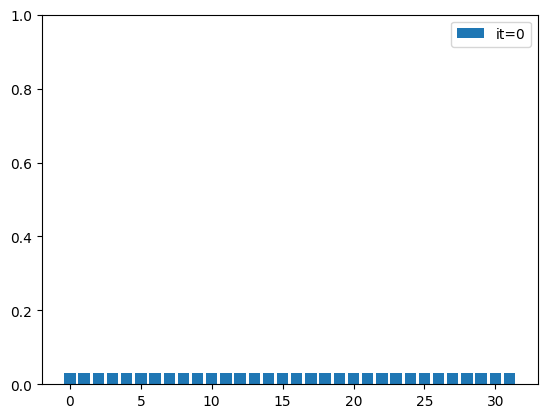

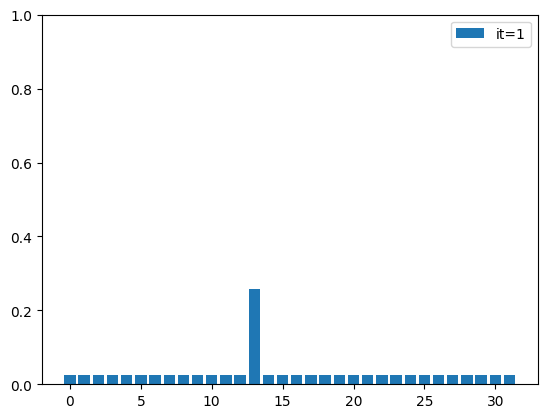

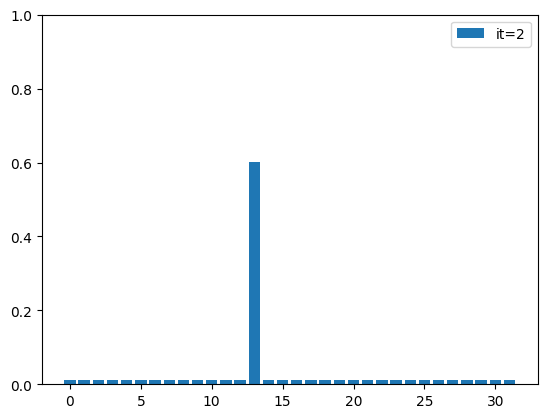

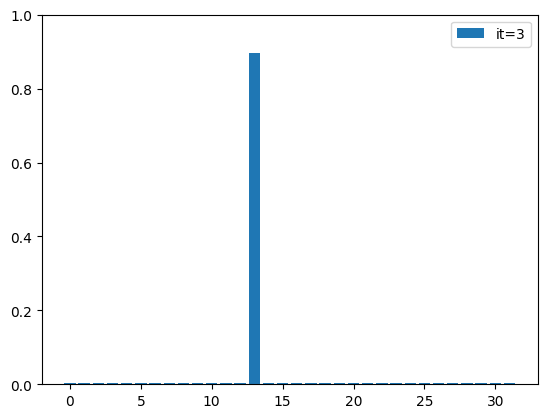

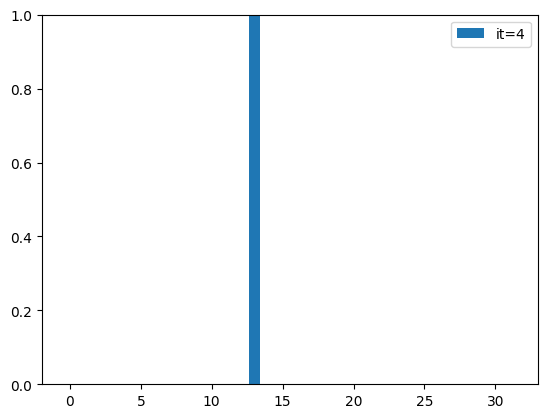

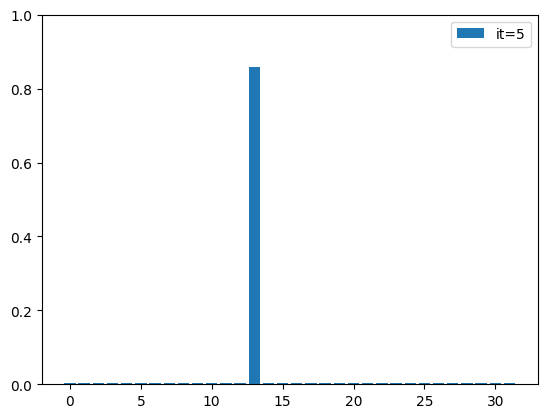

In [5]:
for n in range(6):
    plt.bar(
        list(range(2 ** n_bits)),
        grover(num_its=n),
        label=f"it={n}"
    )
    plt.ylim(0, 1)
    plt.legend()
    plt.show()